In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Environment is ready!")

Environment is ready!


In [3]:
df = pd.read_csv("../data/netflix_titles_cleaned.csv")

## 1. Exploratory Data Analysis

This section explores the Netflix dataset to understand its
structure, content distribution, and key characteristics.

In [4]:
# Dataset dimensions
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Dataset information
df.info()

Number of records: 8807
Number of columns: 12

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      8807 non-null   str  
 4   cast          8807 non-null   str  
 5   country       8807 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8807 non-null   str  
 9   duration      8807 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


## 1.2 Missing values and duplicates

In [5]:
# Check missing values
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values[missing_values > 0])

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

Missing values:
date_added    10
dtype: int64

Duplicate records: 0


## 1.3 Statistical summary

In [6]:
df.describe(include='all')

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,8807,8807,8807,8797,8807.000000,8807,8807,8807,8807
unique,8807,2,8806,4529,7693,749,1714,NaN,18,221,514,8775
top,s1,Movie,Consequences,Unknown,Unknown,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,2,2634,825,2818,110,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


## 2. Univariate analysis
    Here, we'll investigate individual variables.
### 2.1 Movies vs TV Shows
    First, calculate the frequency and percentage.

In [7]:
# Frequency
content_count = df['type'].value_counts()

# Percentage
content_percentage = df['type'].value_counts(normalize=True) * 100

# Combine into a DataFrame
content_distribution = pd.DataFrame({
    'Frequency': content_count,
    'Percentage': content_percentage.round(2)
})

content_distribution

,Frequency,Percentage
type,,
Movie,6131,69.62
TV Show,2676,30.38


### Visualisation: Movies vs TV Shows

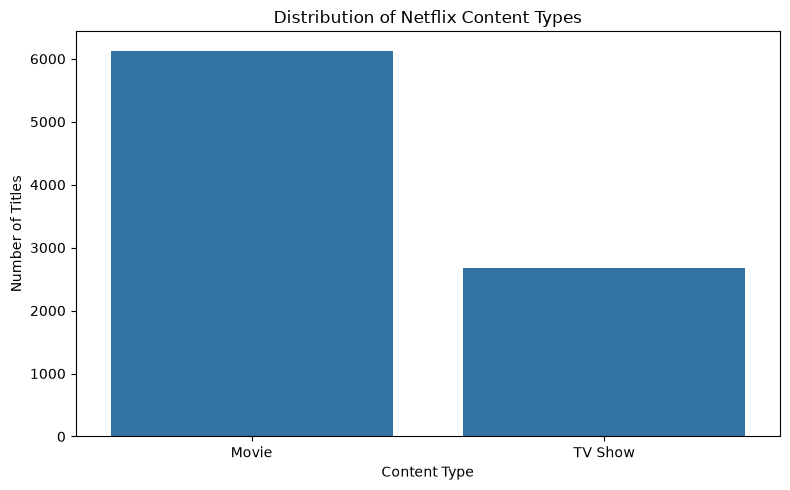

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='type')

plt.title('Distribution of Netflix Content Types')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')

plt.tight_layout()
plt.show()

## 3. Bivariate analysis
Now we'll examine relationships and comparisons between variables.
### 3.1 Content production over the years
We want to understand how Netflix titles are distributed across release years.

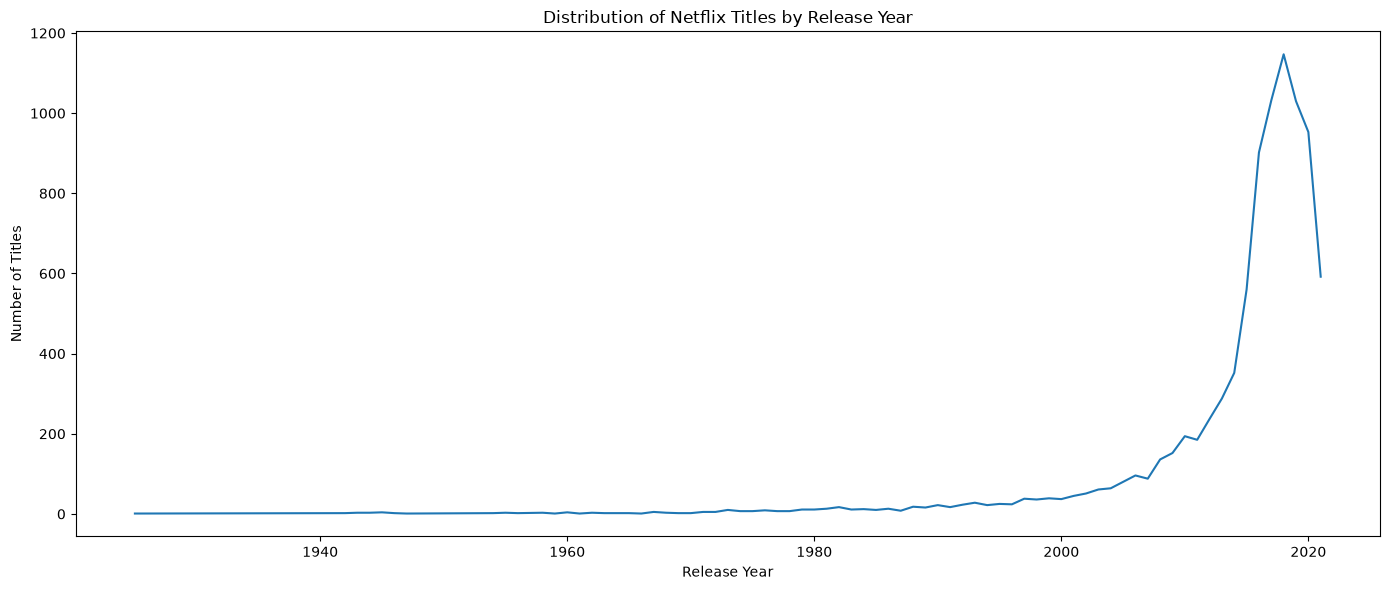

In [9]:
# Count titles by release year
yearly_content = df['release_year'].value_counts().sort_index()

# Visualisation
plt.figure(figsize=(14, 6))

plt.plot(yearly_content.index, yearly_content.values)

plt.title('Distribution of Netflix Titles by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.tight_layout()
plt.show()

### Compare Movies and TV Shows by release year

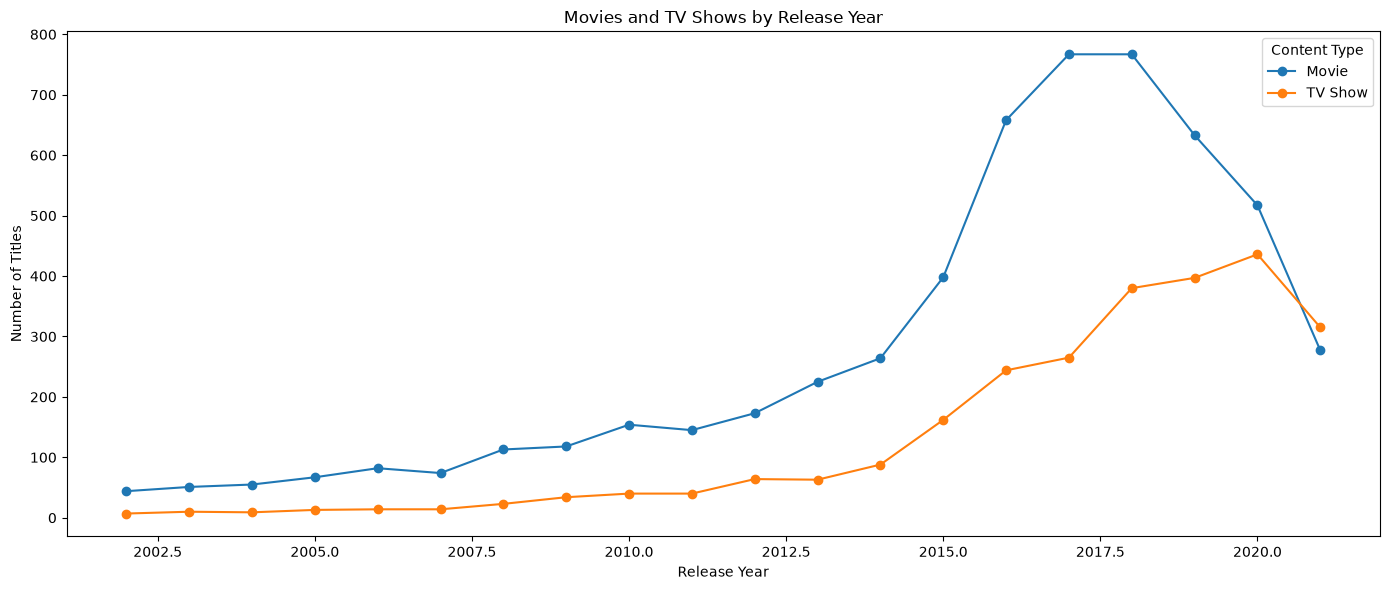

In [10]:
yearly_type = df.groupby(
    ['release_year', 'type']
).size().unstack(fill_value=0)

yearly_type.tail(20).plot(
    figsize=(14, 6),
    marker='o'
)

plt.title('Movies and TV Shows by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.legend(title='Content Type')

plt.tight_layout()
plt.show()

### 3.2 Distribution of content ratings
Let's investigate the ratings assigned to Netflix titles.

In [11]:
rating_count = df['rating'].value_counts()

rating_count

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
Unknown        4
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64

### Visualisation:

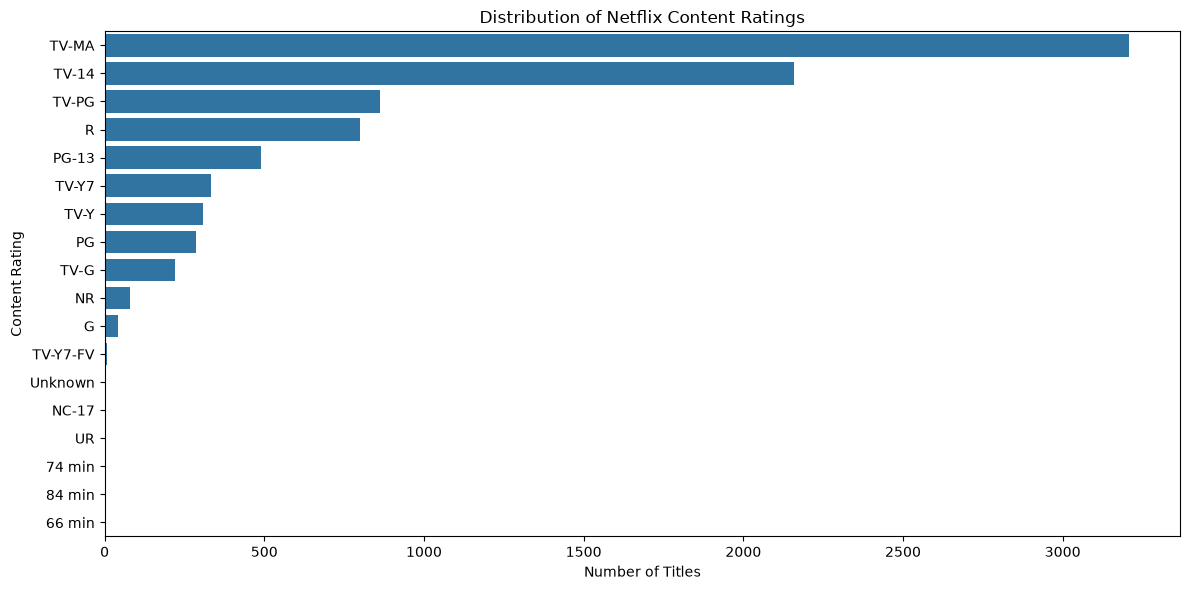

In [12]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='rating',
    order=df['rating'].value_counts().index
)

plt.title('Distribution of Netflix Content Ratings')
plt.xlabel('Number of Titles')
plt.ylabel('Content Rating')

plt.tight_layout()
plt.show()

## 4. Country analysis
Let's investigate which countries contribute the most titles.

In [13]:
country_df = df[df['country'] != 'Unknown'].copy()

country_df['country'] = country_df['country'].str.split(', ')

country_df = country_df.explode('country')

top_countries = country_df['country'].value_counts().head(10)

top_countries

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64

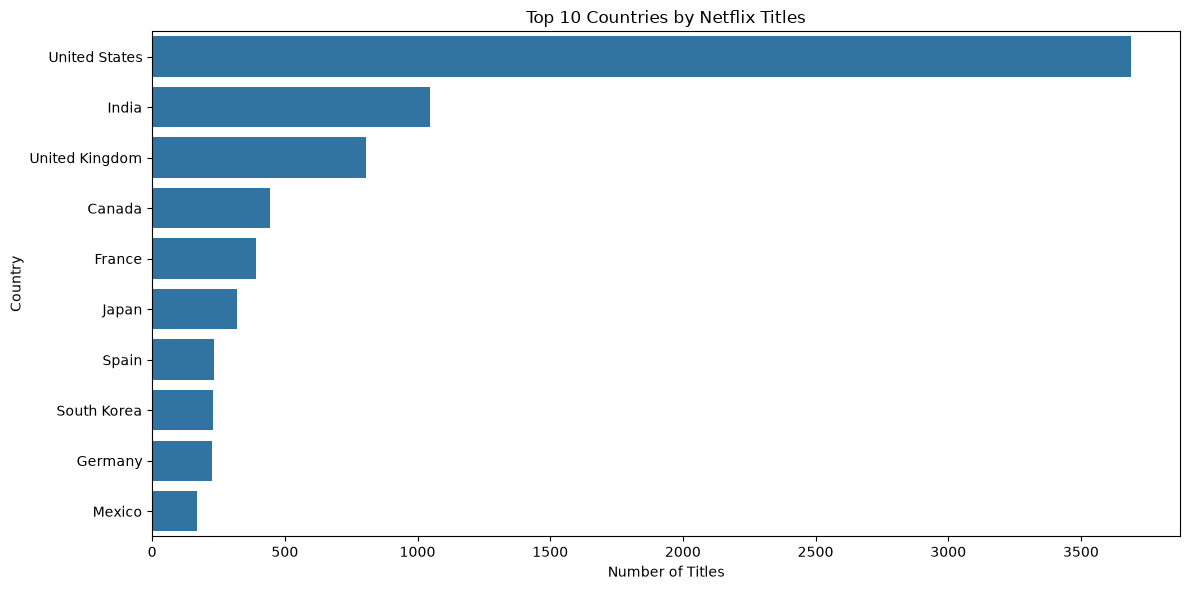

In [14]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title('Top 10 Countries by Netflix Titles')
plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

## 5. Genre analysis
The listed_in column contains the genres associated with each title.

In [15]:
genre_df = df.copy()

genre_df['listed_in'] = genre_df['listed_in'].str.split(', ')

genre_df = genre_df.explode('listed_in')

top_genres = genre_df['listed_in'].value_counts().head(15)

top_genres

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
TV Comedies                  581
Thrillers                    577
Crime TV Shows               470
Kids' TV                     451
Docuseries                   395
Name: count, dtype: int64

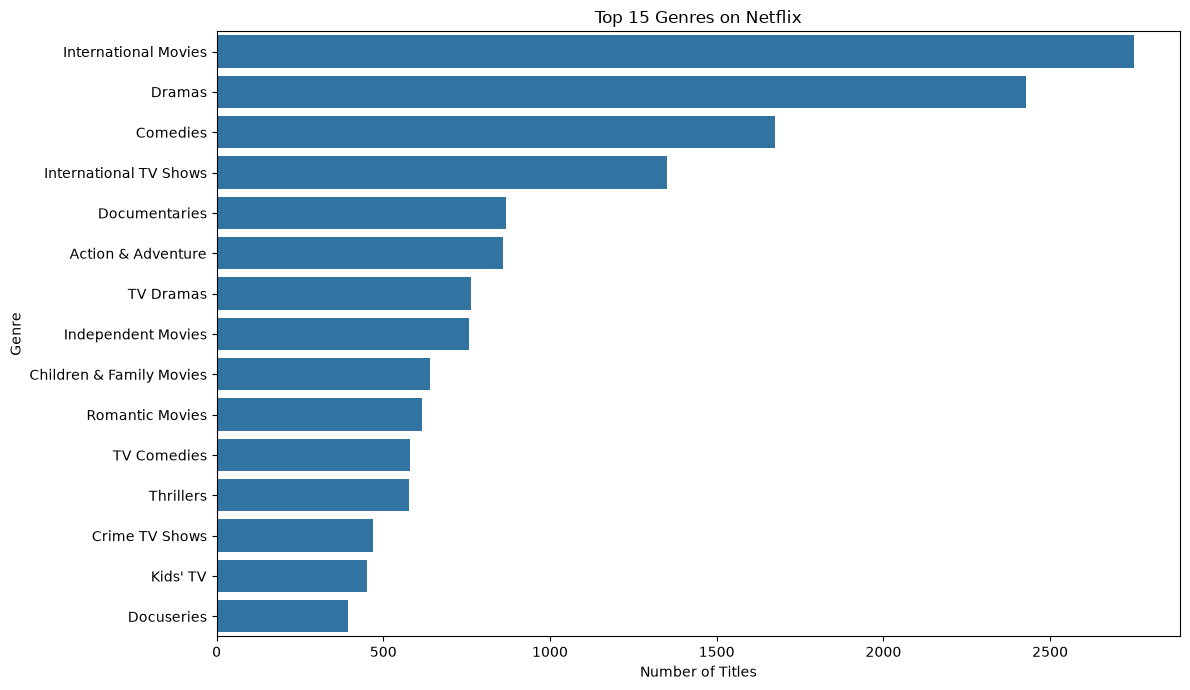

In [16]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title('Top 15 Genres on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')

plt.tight_layout()
plt.show()

## 6. Movie duration analysis
Movies have their duration recorded in minutes, while TV shows have their duration recorded in seasons.

In [17]:
movies = df[df['type'] == 'Movie'].copy()

movies['duration_minutes'] = (
    movies['duration']
    .str.extract(r'(\d+)')
    .astype(float)
)

movies['duration_minutes'].describe()

count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_minutes, dtype: float64

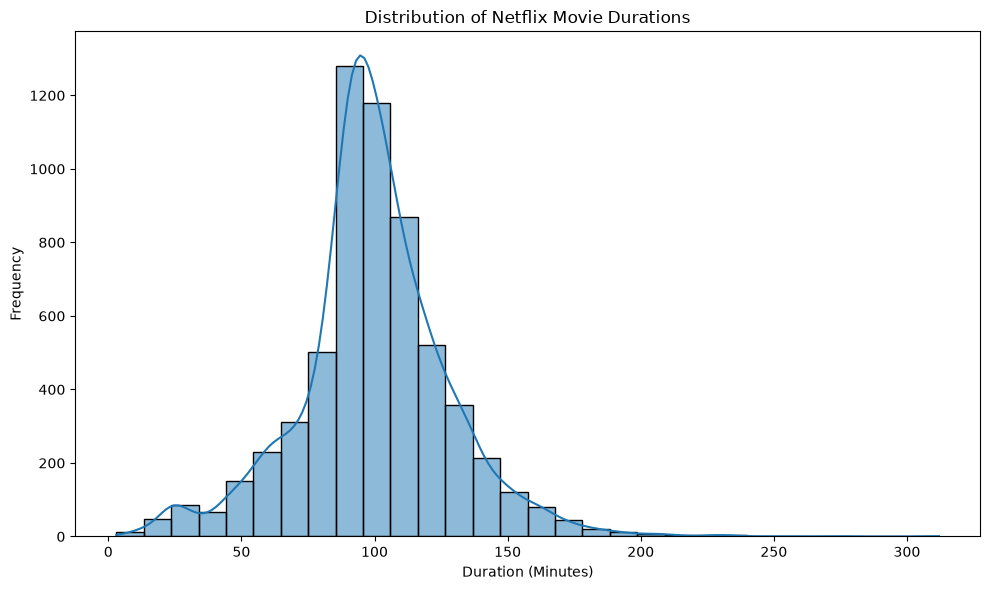

In [20]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=movies,
    x='duration_minutes',
    bins=30,
    kde=True
)

plt.title('Distribution of Netflix Movie Durations')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.savefig('../visuals/content_distribution.png', dpi=300)
plt.show()

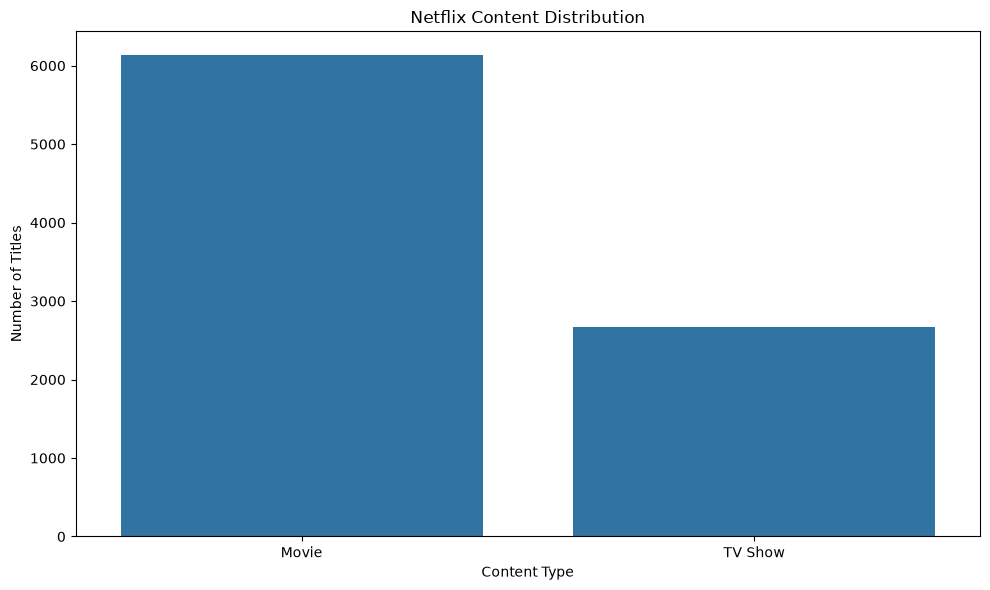

In [19]:
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x='type')

plt.title('Netflix Content Distribution')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')

plt.tight_layout()

plt.savefig('../visuals/content_distribution.png', dpi=300)

plt.show()